In [1]:
import copy
import os
import math
import time

import numpy as np
import torch
from torch import nn, Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from typing import Literal, Tuple, Callable, NamedTuple
import pandas as pd

SEED = 2021
np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [3]:
def attention(Q, K, V):
    """Scaled dot product attention (notebook 3); broadcasts over any
    leading batch axes."""
    d = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d)
    weights = F.softmax(scores, dim=-1)
    return weights @ V, weights


class MultiHeadAttention(nn.Module):
    """Multi-head attention with learned projections (notebook 4)."""
    def __init__(self, num_hiddens: int, num_heads: int):
        super().__init__()

        self.num_heads = num_heads
        self.W_q = nn.Linear(num_hiddens, num_hiddens, bias=True)
        self.W_k = nn.Linear(num_hiddens, num_hiddens, bias=True)
        self.W_v = nn.Linear(num_hiddens, num_hiddens, bias=True)
        self.W_o = nn.Linear(num_hiddens, num_hiddens, bias=True)

    def split_heads(self, X: Tensor):
        """(batch, seq, num_hiddens) -> (batch, heads, seq, num_hiddens/heads)"""
        b, seq, _ = X.shape
        return X.reshape(b, seq, self.num_heads, -1).transpose(1, 2)

    def merge_heads(self, X: Tensor):
        """(batch, heads, seq, d_head) -> (batch, seq, num_hiddens)"""
        b, h, seq, d_head = X.shape
        return X.transpose(1, 2).reshape(b, seq, h * d_head)

    def forward(self, queries: Tensor, keys: Tensor, values: Tensor):
        """
        Input: (batch, seq, num_hiddens)
        Output: (batch, seq, num_hiddens)
        """
        # project, then split into heads: each is (batch, heads, seq, d_head)
        Q = self.split_heads(self.W_q(queries))   # (batch, heads, seq, d_head)
        K = self.split_heads(self.W_k(keys))
        V = self.split_heads(self.W_v(values))
        output, self.attention_weights = attention(Q, K, V)
        return self.W_o(self.merge_heads(output))


class PositionWiseFFN(nn.Module):
    """
    The same two-layer MLP applied at every position from class,
    but this time with GELU activation and dropout applied in the FFN.
    """
    def __init__(self, num_hiddens: int, ffn_num_hiddens: int, dropout: float):
        super().__init__()

        # nn.Linear acts on the last dimension, i.e., on each position separately.
        self.net = nn.Sequential(
            nn.Linear(num_hiddens, ffn_num_hiddens),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ffn_num_hiddens, num_hiddens))


    def forward(self, X: Tensor):
        """
        Input: (batch, seq, num_hiddens)
        Output: (batch, seq, num_hiddens)
        """
        return self.net(X)


class AddNorm(nn.Module):
    def __init__(self, num_hiddens, dropout):
        super().__init__()

        # NOTE: the use of BatchNorm here instead of LayerNorm.
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.BatchNorm1d(num_hiddens)

    def forward(self, X: Tensor, Y: Tensor):
        """
        Input: X (batch, seq, num_hiddens),
               Y (batch, seq, num_hiddens)
        Output: (batch, seq, num_hiddens)
        """
        # X: the sublayer's input; Y: the sublayer's output
        residual_update = self.dropout(Y) + X
        return self.norm(residual_update.transpose(1, 2)).transpose(1, 2)


class TransformerEncoderBlock(nn.Module):
    def __init__(self, num_hiddens: int, ffn_num_hiddens: int, num_heads: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(num_hiddens, num_heads)
        self.addnorm1 = AddNorm(num_hiddens, dropout)
        self.ffn = PositionWiseFFN(num_hiddens, ffn_num_hiddens, dropout)
        self.addnorm2 = AddNorm(num_hiddens, dropout)

    def forward(self, X: Tensor):
        """
        Input/Output: (batch * num_channels, num_patches, num_hiddens)
        """
        Y = self.addnorm1(X, self.attention(X, X, X))
        return self.addnorm2(Y, self.ffn(Y))


class PatchPositionalEmbedding(nn.Module):
    """
    Produce 'embeddings' of patches through:
    - A linear project that maps patches in dimension `p` to dimension `d = num_hiddens`.
    - A trained lookup matrix that encodes position of `N` patches.

    Output of this layer is flattened in the (batch x channel) dimension so input into
    MultiHeadAttention is the standard (samples, sequence, embed_d) shape.
    """
    def __init__(self, num_patches: int, patch_size: int, num_hiddens: int):
        super().__init__()
        self.W_patch = nn.Linear(patch_size, num_hiddens, bias=True)

        W_position = torch.empty((num_patches, num_hiddens))
        nn.init.uniform_(W_position, -0.02, 0.02)
        self.W_position = nn.Parameter(W_position)

    def forward(self, X: Tensor):
        """
        Input: (batch * num_channels, num_patches, patch_size)
        Output: (batch * num_channels, num_patches, num_hiddens)
        """
        return self.W_patch(X) + self.W_position


class Patcher(nn.Module):
    def __init__(self, patch_size: int, stride: int):
        super().__init__()
        self.patch_size = patch_size
        self.stride = stride
        self.padding = nn.ReplicationPad1d((0, stride))

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, num_patches, patch_size)
        """
        return self.padding(X).unfold(dimension=-1, size=self.patch_size, step=self.stride)


class RevIN(nn.Module):
    """
    Reversible Instance Normalization: Normalize each time series (channel) with zero
    mean and a std dev of 1. Reverse this procedure when `'denorm'`ing.

    The official PatchTST implementation released with the paper uses the implementation
    from https://github.com/ts-kim/RevIN/blob/master/RevIN.py, copied here.

    MIT License

    Copyright (c) 2022 Electronics and Telecommunications Research Institute (ETRI)

    Permission is hereby granted, free of charge, to any person obtaining a copy
    of this software and associated documentation files (the "Software"), to deal
    in the Software without restriction, including without limitation the rights
    to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
    copies of the Software, and to permit persons to whom the Software is
    furnished to do so, subject to the following conditions:

    The above copyright notice and this permission notice shall be included in all
    copies or substantial portions of the Software.

    THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
    IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
    FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
    AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
    LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
    OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
    SOFTWARE.
    """
    def __init__(self, num_features: int, eps=1e-5, affine=True):
        """
        :param num_features: the number of features or channels
        :param eps: a value added for numerical stability
        :param affine: if True, RevIN has learnable affine parameters
        """
        super(RevIN, self).__init__()
        self.num_features = num_features
        self.eps = eps
        self.affine = affine
        if self.affine:
            self._init_params()

    def forward(self, x, mode: Literal["norm"]|Literal["denorm"]):
        """
        Input/Output: (batch, num_channels, lookback_size)
        Original code works on the last two dimensions transposed.
        """
        x = x.transpose(1, 2)
        if mode == 'norm':
            self._get_statistics(x)
            x = self._normalize(x)
        elif mode == 'denorm':
            x = self._denormalize(x)
        else: raise NotImplementedError

        x = x.transpose(1, 2)
        return x

    def _init_params(self):
        # initialize RevIN params: (C,)
        self.affine_weight = nn.Parameter(torch.ones(self.num_features))
        self.affine_bias = nn.Parameter(torch.zeros(self.num_features))

    def _get_statistics(self, x):
        dim2reduce = tuple(range(1, x.ndim-1))
        self.mean = torch.mean(x, dim=dim2reduce, keepdim=True).detach()
        self.stdev = torch.sqrt(torch.var(x, dim=dim2reduce, keepdim=True, unbiased=False) + self.eps).detach()

    def _normalize(self, x):
        x = x - self.mean
        x = x / self.stdev
        if self.affine:
            x = x * self.affine_weight
            x = x + self.affine_bias
        return x

    def _denormalize(self, x):
        if self.affine:
            x = x - self.affine_bias
            x = x / (self.affine_weight + self.eps*self.eps)
        x = x * self.stdev
        x = x + self.mean
        return x


class PatchTSTParams(NamedTuple):
    num_channels: int  # Number of individual time series in multivariate series.
    patch_size: int=16
    stride: int=8
    lookback_size: int=512
    prediction_size: int=96
    num_hiddens: int=128
    ffn_num_hiddens: int=256
    num_heads: int=16
    num_blocks: int=3
    dropout: float=0.2

    def __str__(self):
        return f"PatchTST(M={self.num_channels}, L={self.lookback_size}, T={self.prediction_size})"


class PatchTST(nn.Module):
    """
    PatchTST architecture. Default parameter values are from the original paper.

    The default lookback window size of 512 time steps produces 64 patches with the
    default patch size of 16 and stride of 8. Another common variant is a
    lookback size of 336, producing 42 patches.

    The original paper tests models over prediction time horizons of 96, 192, 336,
    and 720. In the official source code, dropout is applied after positional encoding
    and in the transformer encoder block.
    """
    def __init__(self, args: PatchTSTParams):
        super().__init__()
        self.args = args
        self.num_patches = int((args.lookback_size - args.patch_size) / args.stride) + 2

        # Normalization layer standardizes each channel individually.
        self.norm = RevIN(num_features=args.num_channels)
        self.patch = Patcher(args.patch_size, args.stride)
        self.embedding = PatchPositionalEmbedding(self.num_patches, args.patch_size, args.num_hiddens)
        self.dropout = nn.Dropout(args.dropout)

        self.blks = nn.ModuleList([
            TransformerEncoderBlock(args.num_hiddens, args.ffn_num_hiddens, args.num_heads, args.dropout)
            for _ in range(args.num_blocks)
        ])

        self.decoder = nn.Sequential(
            nn.Flatten(start_dim=-2),
            nn.Linear(self.num_patches * args.num_hiddens, args.prediction_size))

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, prediction_size)

        Each channel is one time series from the multivariate series.
        """
        batch, num_channels, _ = X.shape

        # (batch, num_channels, num_patches, patch_size)
        patched_X = self.patch(self.norm(X, mode="norm"))
        assert self.num_patches == patched_X.shape[2]

        # (batch * num_channels, num_patches, num_hiddens)
        # Batch and channels flattened together.
        X_batch_channel_flattened = patched_X.flatten(start_dim=0, end_dim=1)
        patch_embeds: Tensor = self.dropout(self.embedding(X_batch_channel_flattened))

        for blk in self.blks:
            patch_embeds = blk(patch_embeds)

        # (batch, num_channels, num_patches, num_hiddens)
        # NOTE: The official code transposes the last two dimensions before feeding into
        # the decoder head. It shouldn't matter, but perhaps worth investigating if this
        # doesn't perform...
        patch_embeds = patch_embeds.unflatten(dim=0, sizes=(batch, num_channels))
        predictions = self.decoder(patch_embeds)
        return self.norm(predictions, mode="denorm")

In [5]:
def load_time_series_data(
    file_path: str,
    delimiter: str = ",",
) -> np.ndarray:
    """
    Load raw multivariate time-series data into a 2D float tensor of shape (T, num_channels).

    The file is expected to be a text file with no header row or index (time) column. I.e., it
    should directly be raw data rows. Each row must record a timestamp, and each column a channel
    of the multivariate series.
    """
    arr = np.loadtxt(file_path, delimiter=delimiter)
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D tensor of shape (T, num_channels), got shape {arr.shape}")

    return arr


def to_data_loader(data: TensorDataset, batch_size: int, shuffle=False, seed=SEED) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)

    return DataLoader(
        data,
        batch_size,
        shuffle=shuffle,
        generator=g)


def split_time_series_data(
    raw_data: np.ndarray,
    lookback_size: int,
    prediction_size: int,
    split_ratios: Tuple[float, float, float] = (0.7, 0.1, 0.2),
    batch_size: int = 24,
    dtype: torch.dtype = torch.float32,
) -> Tuple[DataLoader, DataLoader, DataLoader, StandardScaler]:
    """
    Construct a PyTorch TensorDataset containing (X, Y) sliding-window pairs. Each window pair
    logically consists of X_i = [...lookback_size...] historic time steps used to predict
    Y_i = [...prediction_size...] events into the future, for each channel.

    In other words,
        X[i] = data[i : i + lookback_size]^T    shape: (num_channels, lookback_size)
        Y[i] = data[i + lookback_size : i + lookback_size + prediction_size]^T
                                                shape: (num_channels, prediction_size)
    Returns:
       train/val/test: `DataLoader`s, containing `TensorDataset`s that have:
                tensors[0] (X): shape (N, num_channels, lookback_size)
                tensors[1] (Y): shape (N, num_channels, prediction_size)
            where N is the number of valid sliding windows. Data is standardized.

        scaler: the `StandardScaler` used to standardize the data, in order to
            reverse the process for plotting in the original scale of the data.
    """
    scaler = StandardScaler()
    has_fit = False
    def lookback_and_prediction_windows(split: np.ndarray) -> TensorDataset:
        nonlocal scaler, has_fit
        split = scaler.transform(split) if has_fit else scaler.fit_transform(split)
        has_fit = True

        # Stride of 1: heavily overlap samples.
        tensor = torch.from_numpy(split).to(dtype=dtype)
        X = tensor.unfold(dimension=0, size=lookback_size, step=1)
        Y = tensor[lookback_size:].unfold(dimension=0, size=prediction_size, step=1)

        num_samples = min(X.shape[0], Y.shape[0])
        return TensorDataset(X[:num_samples], Y[:num_samples])

    num_timesteps, _ = raw_data.shape

    train_ratio, val_ratio, _ = split_ratios
    train_size = int(num_timesteps * train_ratio)
    val_size = int(num_timesteps * val_ratio)
    test_size = num_timesteps - train_size - val_size

    # Pull lookback windows in val/test from the split before it (predicted values
    # in val/test are never seen from another split).
    train_dataset, val_dataset, test_dataset = map(lookback_and_prediction_windows, [
        raw_data[:train_size],
        raw_data[train_size - lookback_size:train_size + val_size],
        raw_data[num_timesteps - test_size - lookback_size:],
    ])

    # TODO(ianfisk): Official code uses drop_last=True in train/val/test loaders. Test here.
    return to_data_loader(train_dataset, batch_size, shuffle=True), \
            to_data_loader(val_dataset, batch_size), \
            to_data_loader(test_dataset, batch_size), \
            scaler

In [12]:
def train_epoch(model: nn.Module, train_loader: DataLoader, loss_fn, optimizer) -> float:
    model.train()
    total_loss = 0.0   # sum of per-example losses
    total_examples = 0
    for X, y in train_loader:
        # Typical training workflow: Dataset/loader are on the CPU.
        # Just load one batch to the GPU.
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss = loss_fn(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # loss_fn returns the mean over the batch, so multiply back out by the
        # batch size to accumulate an exact, example-weighted average (the final
        # batch is smaller, so a plain mean of batch means would be biased).
        total_loss += loss.item() * y.numel()
        total_examples += y.numel()

    return total_loss / total_examples


def evaluate(model: nn.Module, data_loader: DataLoader, loss_fn) -> float:
    model.eval()
    total_loss = 0.0
    total = 0
    with torch.no_grad():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            y_pred = model(X)
            total_loss += loss_fn(y_pred, y).item() * y.numel()
            total += y.numel()
    return total_loss / total


def train_early_stopping(
        model: nn.Module,
        train_loader,
        valid_loader,
        loss_fn,
        optimizer,
        epochs,
        verbose=False) -> tuple[list[float], list[float]]:
    best_val_loss = float('inf')
    patience_counter = 0
    patience = 5          # number of epochs to wait for an improvement
    best_state = None

    train_losses, valid_losses = [], []
    for epoch in range(epochs):
        start = time.time()
        train_loss = train_epoch(model, train_loader, loss_fn, optimizer)
        val_loss = evaluate(model, valid_loader, loss_fn)
        if verbose:
            print(f'epoch {epoch + 1:2d}  train loss {train_loss:.3f}  '
                f'val loss {val_loss:.3f}  '
                f'({time.time() - start:.0f}s)')

        train_losses.append(train_loss)
        valid_losses.append(val_loss)

        if val_loss < best_val_loss:
            # still improving: remember this model as the best so far
            best_val_loss = val_loss
            patience_counter = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            # not better than our current best.  keep training for a few more epochs
            # to give it a chance to improve (that is what `patience` controls)
            patience_counter += 1
            if patience_counter >= patience:
                break

    # Restore the best weights before evaluating. Large LRs will fail
    # to produce a validation loss < best_val_loss. Don't restore to
    # anything in this case.
    if best_state:
        model.load_state_dict(best_state)

    return train_losses, valid_losses


def plot_loss(
    train_losses: list[float],
    val_losses: list[float],
    title: str = ""
):
    epochs_axis = range(1, len(train_losses) + 1)
    _, ax_loss = plt.subplots(figsize=(4, 2.4))

    l1 = ax_loss.plot(epochs_axis, train_losses, label='training loss')
    l2 = ax_loss.plot(epochs_axis, val_losses, label='validation loss')
    ax_loss.set_xlabel('epoch')
    ax_loss.set_ylabel('loss')

    lines = l1 + l2
    ax_loss.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.3, 1), loc='upper left')
    plt.title(title)


class ExperimentRunner:
    """
    A class that facilitates experimenting with different model configurations.
    Each added experiment gets `n` models trained with a different random seed (`n = 5`).
    Averaged results are returned in a dataframe after evaluating the models against
    the validation set. Plotting some/all of the experiments is also possible.
    """
    REPORT_COLUMNS = ["Classifier", "Loss (val)", "Epochs", "Param count"]

    # Results used in plots, saved in case we want to recall results from this
    # runner without re-running all experiments.
    class ExpResults(NamedTuple):
        params: NamedTuple
        model: nn.Module
        train_losses: list[float]
        val_losses: list[float]

    def __init__(self, model_constr: Callable[[NamedTuple], nn.Module]):
        self.model_constr = model_constr

        # Subclass used for hyperparams. E.g., TDNNHyperParams. Model must be
        # constructable by running model_constr(experiment_params).
        self.experiments: list[NamedTuple] = []
        self.experiments_to_plot: set[str] = set()
        self.experiment_results: list[ExperimentRunner.ExpResults] = []

        self.epochs: int = -1
        self.lr: float = 0.0001
        self.train_loader = None
        self.val_loader = None

    def with_epochs(self, epochs: int) -> ExperimentRunner:
        self.epochs = epochs
        return self

    def with_lr(self, lr: float) -> ExperimentRunner:
        self.lr = lr
        return self

    def with_data(self, train_loader: DataLoader, val_loader: DataLoader) -> ExperimentRunner:
        self.train_loader = train_loader
        self.val_loader = val_loader
        return self

    def add_experiments(self, *params) -> ExperimentRunner:
        self.experiments.extend(params)
        return self

    def and_plot(self, *params) -> ExperimentRunner:
        """Plot a given set of hyper params. These must match planned experiments."""
        self.experiments_to_plot.update(map(str, params))
        return self

    def with_plots(self) -> ExperimentRunner:
        """Plot all experiments recorded thus far when this runner is executed."""
        self.experiments_to_plot.update(map(str, self.experiments))
        return self

    def get_results(self) -> list[ExperimentRunner.ExpResults]:
        return self.experiment_results.copy()

    def run(self, verbose=False) -> pd.DataFrame:
        run_data = []
        for params in self.experiments:
            plot_name = None
            serialized_params = str(params)
            print(f"Running experiment: {params}")

            if serialized_params in self.experiments_to_plot:
                plot_name = serialized_params

            model = self.model_constr(params).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=self.lr)
            loss_fn = nn.MSELoss()

            train_losses, val_losses = train_early_stopping(
                model,
                self.train_loader,
                self.val_loader,
                loss_fn,
                optimizer,
                self.epochs,
                verbose=verbose)
            self.experiment_results.append(ExperimentRunner.ExpResults(
                params=params,
                model=model.cpu(),
                train_losses=train_losses,
                val_losses=val_losses))
            if plot_name:
                plot_loss(
                    train_losses=train_losses,
                    val_losses=val_losses,
                    title=plot_name,
                )

            param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
            actual_epochs = len(train_losses)
            run_data.append([serialized_params, min(val_losses), actual_epochs, param_count])

        df = pd.DataFrame(
            run_data,
            columns=self.REPORT_COLUMNS
        )
        return df.round(4).astype(object).fillna("Diverged")


In [13]:
# Take only 100 channels to avoid the GPU from running out of memory.
# TODO(ianfisk): Randomize this? Pick a smaller, more interesting dataset?
raw_data = load_time_series_data("./data/traffic.txt", delimiter=",")[:, 0:100]
raw_data.shape

(17544, 100)

In [14]:
train_loader, val_loader, test_loader, scaler = split_time_series_data(
    raw_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=12)  # For less memory allocation.

example_batch_X, example_batch_Y = next(iter(train_loader))
print(f"batch_X shape: {example_batch_X.shape}")
print(f"batch_y shape: {example_batch_Y.shape}")

batch_X shape: torch.Size([12, 100, 512])
batch_y shape: torch.Size([12, 100, 96])


Running experiment: PatchTST(M=100, L=512, T=96)
epoch  1  train loss 0.281  val loss 0.228  (141s)
epoch  2  train loss 0.245  val loss 0.228  (142s)
epoch  3  train loss 0.237  val loss 0.227  (142s)
epoch  4  train loss 0.233  val loss 0.223  (142s)
epoch  5  train loss 0.229  val loss 0.220  (142s)
epoch  6  train loss 0.226  val loss 0.222  (142s)
epoch  7  train loss 0.223  val loss 0.218  (142s)
epoch  8  train loss 0.221  val loss 0.217  (167s)
epoch  9  train loss 0.219  val loss 0.216  (280s)
epoch 10  train loss 0.217  val loss 0.215  (280s)
epoch 11  train loss 0.215  val loss 0.216  (280s)
epoch 12  train loss 0.213  val loss 0.214  (280s)
epoch 13  train loss 0.212  val loss 0.214  (280s)
epoch 14  train loss 0.211  val loss 0.214  (278s)
epoch 15  train loss 0.210  val loss 0.212  (280s)
epoch 16  train loss 0.208  val loss 0.211  (278s)
epoch 17  train loss 0.207  val loss 0.213  (280s)
epoch 18  train loss 0.206  val loss 0.211  (280s)
epoch 19  train loss 0.205  val l

,Classifier,Loss (val),Epochs,Param count
0,"PatchTST(M=100, L=512, T=96)",0.205,36,1194536


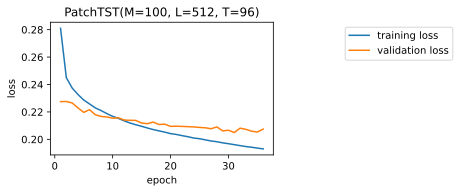

In [10]:
runner = (
    ExperimentRunner(PatchTST)
        .with_epochs(400)
        .with_data(train_loader, val_loader)
        .add_experiments(
            PatchTSTParams(
                num_channels=100,
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

results = runner.run(verbose=True)
results

In [11]:
allocated = torch.cuda.memory_allocated() / (1024 ** 3)
reserved = torch.cuda.memory_reserved() / (1024 ** 3)
peak = torch.cuda.max_memory_allocated() / (1024 ** 3)

print(f"Allocated: {allocated:.2f} GB | Reserved: {reserved:.2f} GB | Peak: {peak:.2f} GB")


Allocated: 0.24 GB | Reserved: 3.29 GB | Peak: 3.11 GB
